In [1]:
import pandas as pd
from ete3 import Tree

PATH = "/Users/aleksandradenisova/Laboratory/innovation/Inno_2025/initial_data/"

# tree from https://github.com/eliotmiller/clootl
# doi: https://doi.org/10.64898/2026.04.23.720449 

tree = Tree(f"{PATH}/tree_clootl.newick", format=1)
df_innovation = pd.read_csv(
    f"{PATH}/ALLBIRDTRAITS_Database_March_2026.csv",
)
df_innovation["Order"] = df_innovation["Order"].apply(lambda x: x.strip("\t").upper())

domesticated_birds = [
    "Gallus_gallus", "Anser_anser", "Anas_platyrhynchos"
]
df_innovation = df_innovation[~df_innovation["Species"].isin(domesticated_birds)]

In [4]:
df_vgp = pd.read_csv(
    f"{PATH}/annotations.tsv", sep = "\t"
)
df_vgp_birds = df_vgp[df_vgp["Lineage"] == "Birds"]
df_vgp_birds["ScientificName"] = df_vgp_birds["ScientificName"].apply(lambda x: x.lower().capitalize())
df_vgp_birds["Species"] = df_vgp_birds["ScientificName"].str.replace(" ", "_")

phylo_root = "/Users/aleksandradenisova/Laboratory/innovation/Inno_2025/cognitive_evolution/data/"
df_vgp_birds.to_csv(f"{phylo_root}/vgp_birds.csv", index=False)

df_innovation_vgp = df_innovation.merge(df_vgp_birds[["Species", '# accession']], on="Species", how="inner")

df_innovation_vgp["ResearchEffort"].describe(
    percentiles=[i / 10 for i in range(1, 10)]
)

/var/folders/fc/n8rj9g1j6_x12_dl3p0fqv7c0000gn/T/ipykernel_57863/4215872444.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_vgp_birds["ScientificName"] = df_vgp_birds["ScientificName"].apply(lambda x: x.lower().capitalize())
/var/folders/fc/n8rj9g1j6_x12_dl3p0fqv7c0000gn/T/ipykernel_57863/4215872444.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_vgp_birds["Species"] = df_vgp_birds["ScientificName"].str.replace(" ", "_")


count     109.000000
mean      349.000000
std       442.923683
min         0.000000
10%         6.000000
20%        17.000000
30%        40.200000
40%       128.800000
50%       200.000000
60%       287.800000
70%       409.000000
80%       563.600000
90%       871.200000
max      2092.000000
Name: ResearchEffort, dtype: float64

In [3]:
df_vgp_birds

,# accession,Lineage,Superorder,Orders,Family,Orders_English,MYA,ScientificName,EnglishName,NCBI taxon ID,AssemblyId,asmId,sciName,UCSC_comName,VGPLineage,Species
2,GCA_008658365.1,Birds,Core waterbirds,Charadriiformes,Alcidae,Plovers,65.56,Alca torda,razorbill,28689,bAlcTor1,GCA_008658365.1_bAlcTor1_primary,Alca torda,razorbill (2006_11_07_Graehlm_vinge_78 2019),birds,Alca_torda
3,GCA_009764595.1,Birds,Core landbirds,Passeriformes (Oscines),Parulidae,Songbirds,29.59,Geothlypis trichas,common yellowthroat,135433,bGeoTri1,GCA_009764595.1_bGeoTri1.pri,Geothlypis trichas,common yellowthroat (primary hap 2019),birds,Geothlypis_trichas
4,GCA_009769465.1,Birds,Otidimorphae,Musophagiformes,Musophagidae,Turacos,62.92,Tauraco erythrolophus,red-crested turaco,121530,bTauEry1,GCA_009769465.1_bTauEry1.pri,Tauraco erythrolophus,red-crested turaco (primary hap 2019),birds,Tauraco_erythrolophus
5,GCA_009769525.1,Birds,Columbea,Pterocliformes,Pteroclidae,Sandgrouse,62.67,Pterocles gutturalis,yellow-throated sandgrouse,240206,bPteGut1,GCA_009769525.1_bPteGut1.pri,Pterocles gutturalis,yellow-throated sandgrouse (primary hap 2019),birds,Pterocles_gutturalis
6,GCA_009769605.1,Birds,Core landbirds,Bucerotiformes,Bucorvidae,Hornbills,51.96,Bucorvus abyssinicus,Abyssinian ground hornbill,153643,bBucAby1,GCA_009769605.1_bBucAby1.pri,Bucorvus abyssinicus,Abyssinian ground-hornbill (primary hap 2019),birds,Bucorvus_abyssinicus
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
553,GCF_947461875.1,Birds,Core landbirds,Accipitriformes,Accipitridae,Eagles/Osprey,60.41,Haliaeetus albicilla,white-tailed eagle,8969,bHalAlb1,GCF_947461875.1_bHalAlb1.1,Haliaeetus albicilla,white-tailed eagle (primary hap 2022 refseq),birds,Haliaeetus_albicilla
569,GCF_963662255.1,Birds,Core landbirds,Passeriformes (Oscines),Cinclidae,Songbirds,29.59,Cinclus cinclus,white-throated dipper,127875,bCinCin1,GCF_963662255.1_bCinCin1.1,Cinclus cinclus,white-throated dipper (primary hap 2023 refseq),birds,Cinclus_cinclus
573,GCF_963921805.1,Birds,Core waterbirds,Pelicaniformes (Phalacrocoracidae),Phalacrocoracidae,Cormorants/Anhinga,59.40,Phalacrocorax carbo,great cormorant,9209,bPhaCar2,GCF_963921805.1_bPhaCar2.1,Phalacrocorax carbo,great cormorant (primary hap 2024 refseq),birds,Phalacrocorax_carbo
574,GCF_963924245.1,Birds,Core waterbirds,Charadriiformes,Laridae,Plovers,65.56,Chroicocephalus ridibundus,black-headed gull,1192867,bChrRid1,GCF_963924245.1_bChrRid1.1,Chroicocephalus ridibundus,black-headed gull (primary hap 2024 refseq),birds,Chroicocephalus_ridibundus


In [59]:
# filter only species we can trust (with research effort above the threshold)
threshold = 10

df_innovation = df_innovation[
    (df_innovation["ResearchEffort"] >= threshold) | 
    (df_innovation["TECHINNO2025_ResEff"] >= 1.5)
]
df_innovation_vgp = df_innovation.merge(df_vgp_birds["Species"], how = "inner", on = "Species")[
    df_innovation.columns.tolist()
]

print(df_innovation.shape)

df_innovation.head()

(2290, 61)


,Unnamed: 0,Order,Family,Genus,Species,animal,TOTALINNOVATIONS2025,FOODINNO2025,TECHINNO2025,TOTALINNOVATIONS2025_ResEff,...,buildingcoll_mig,lbuildingcoll_mig,buildingcoll_nonmig,lbuildingcoll_nonmig,rawtowercoll,ltowercollnonzero,rawturbinecoll,lturbinecollnonxero,ALLcoll,Abundance.estimate
2,3,PASSERIFORMES,MELIPHAGIDAE,Acanthagenys,Acanthagenys_rufogularis,Acanthagenys_rufogularis,1,1,0,0.307384,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7228371.0
3,4,PASSERIFORMES,ACANTHISITTIDAE,Acanthisitta,Acanthisitta_chloris,Acanthisitta_chloris,1,1,0,0.265218,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1011749.0
5,6,PASSERIFORMES,ACANTHIZIDAE,Acanthiza,Acanthiza_chrysorrhoa,Acanthiza_chrysorrhoa,0,0,0,-0.427929,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6287938.0
9,10,PASSERIFORMES,ACANTHIZIDAE,Acanthiza,Acanthiza_lineata,Acanthiza_lineata,0,0,0,-0.418400,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1924796.0
11,12,PASSERIFORMES,ACANTHIZIDAE,Acanthiza,Acanthiza_reguloides,Acanthiza_reguloides,0,0,0,-0.397411,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1514367.0


In [63]:
df_vgp_birds[df_vgp_birds["Species"].apply(lambda x: x.startswith("Haliaeetus"))]

,# accession,Lineage,Superorder,Orders,Family,Orders_English,MYA,ScientificName,EnglishName,NCBI taxon ID,AssemblyId,asmId,sciName,UCSC_comName,VGPLineage,Species
553,GCF_947461875.1,Birds,Core landbirds,Accipitriformes,Accipitridae,Eagles/Osprey,60.41,Haliaeetus albicilla,white-tailed eagle,8969,bHalAlb1,GCF_947461875.1_bHalAlb1.1,Haliaeetus albicilla,white-tailed eagle (primary hap 2022 refseq),birds,Haliaeetus_albicilla


,Unnamed: 0,Order,Family,Genus,Species,animal,TOTALINNOVATIONS2025,FOODINNO2025,TECHINNO2025,TOTALINNOVATIONS2025_ResEff,...,buildingcoll_mig,lbuildingcoll_mig,buildingcoll_nonmig,lbuildingcoll_nonmig,rawtowercoll,ltowercollnonzero,rawturbinecoll,lturbinecollnonxero,ALLcoll,Abundance.estimate
54,4467,ACCIPITRIFORMES,ACCIPITRIDAE,Haliaeetus,Haliaeetus_albicilla,Haliaeetus_albicilla,1,1,0,-0.34669,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6261559.0


In [41]:
tree_for_tests = Tree(f"{PATH}/tree_clootl.newick", format=1)

overlap = set(df_innovation["Species"].unique().tolist()) & set(tree_for_tests.get_leaf_names())

tree_for_tests.prune(overlap, preserve_branch_length=True)
df_for_tests = df_innovation[df_innovation["Species"].isin(overlap)]

phylo_root = "/Users/aleksandradenisova/Laboratory/innovation/Inno_2025/cognitive_evolution/data/"

tree_for_tests.write(outfile=f"{phylo_root}/tree_clootl_overlap_{threshold}.nwk", format=2)
df_for_tests.to_csv(
    f"{phylo_root}/inno_db_{threshold}_clootl_overlap.csv",
    index=False
)

In [42]:
print(len(tree_for_tests.get_leaf_names()))

1256


In [45]:

!curl https://raw.githubusercontent.com/VGP/vgp-trees/refs/heads/main/phase-1-cactus/multicopy/astralpro.l6.tre > astralpro.l6.tre

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 22432  100 22432    0     0  36350      0 --:--:-- --:--:-- --:--:-- 36297


In [64]:
tree_for_vgp = Tree(f"astralpro.l6.tre", format=1)
tree_for_vgp.prune(set(tree_for_vgp.get_leaf_names()) & set(df_vgp_birds["# accession"].to_list()))

for leaf in tree_for_vgp.iter_leaves():
    leaf.name = df_vgp_birds[df_vgp_birds["# accession"] == leaf.name]["Species"].item()

print(tree_for_vgp)


                                                            /-Ammospiza_maritima
                                                         /-|
                                                        |  |   /-Ammodramus_caudacutus
                                                        |   \-|
                                                      /-|      \-Ammospiza_nelsoni
                                                     |  |
                                                     |  |      /-Melospiza_melodia
                                                     |  |   /-|
                                                   /-|   \-|   \-Melospiza_georgiana
                                                  |  |     |
                                                  |  |      \-Passerculus_sandwichensis
                                                /-|  |
                                               |  |   \-Zonotrichia_albicollis
                                               |  

In [66]:
# tree_for_tests = Tree(f"{PATH}/tree_clootl.newick", format=1)

overlap = set(df_innovation_vgp["Species"].unique().tolist()) & set(tree_for_vgp.get_leaf_names())

tree_for_vgp.prune(overlap, preserve_branch_length=True)
df_for_tests = df_innovation_vgp[df_innovation_vgp["Species"].isin(overlap)]

phylo_root = "/Users/aleksandradenisova/Laboratory/innovation/Inno_2025/cognitive_evolution/data/"

tree_for_vgp.write(outfile=f"{phylo_root}/tree_astralpro.l6.tre_overlap_{threshold}_vgp.nwk", format=2)
df_for_tests.to_csv(
    f"{phylo_root}/inno_db_{threshold}_astralpro.l6.tre_overlap_vgp.csv",
    index=False
)

In [67]:
overlap

{'Acanthisitta_chloris',
 'Acridotheres_tristis',
 'Agelaius_phoeniceus',
 'Alca_torda',
 'Anas_acuta',
 'Anser_brachyrhynchus',
 'Apteryx_mantelli',
 'Apus_apus',
 'Aquila_chrysaetos',
 'Ara_ararauna',
 'Aythya_ferina',
 'Aythya_fuligula',
 'Aythya_marila',
 'Branta_canadensis',
 'Bucephala_clangula',
 'Bucorvus_abyssinicus',
 'Buteo_buteo',
 'Caloenas_nicobarica',
 'Calonectris_borealis',
 'Calypte_anna',
 'Caprimulgus_europaeus',
 'Cariama_cristata',
 'Catharus_ustulatus',
 'Chiroxiphia_lanceolata',
 'Chlamydotis_macqueenii',
 'Ciconia_maguari',
 'Cinclus_cinclus',
 'Clangula_hyemalis',
 'Columba_livia',
 'Corvus_moneduloides',
 'Cuculus_canorus',
 'Cyanocitta_cristata',
 'Cygnus_columbianus',
 'Cygnus_olor',
 'Dromaius_novaehollandiae',
 'Dryobates_pubescens',
 'Erithacus_rubecula',
 'Eudromia_elegans',
 'Falco_biarmicus',
 'Falco_cherrug',
 'Falco_naumanni',
 'Falco_peregrinus',
 'Falco_punctatus',
 'Falco_rusticolus',
 'Fringilla_coelebs',
 'Gallinula_chloropus',
 'Gavia_stellata

In [45]:
tree_for_vgp = Tree(f"{PATH}/tree_clootl.newick", format=1)

overlap = set(df_innovation_vgp["Species"].unique().tolist()) & set(tree_for_vgp.get_leaf_names())

tree_for_vgp.prune(overlap, preserve_branch_length=True)
df_for_tests = df_innovation_vgp[df_innovation_vgp["Species"].isin(overlap)]

phylo_root = "/Users/aleksandradenisova/Laboratory/innovation/Inno_2025/cognitive_evolution/data/"

tree_for_vgp.write(outfile=f"{phylo_root}/tree_vgp_{threshold}_vgp.nwk", format=2)
df_for_tests.to_csv(
    f"{phylo_root}/inno_db_{threshold}_overlap_vgp.csv",
    index=False
)

In [68]:
df_innovation_vgp[df_innovation_vgp["Species"].apply(lambda x: x.startswith("Corvus"))]

,Unnamed: 0,Order,Family,Genus,Species,animal,TOTALINNOVATIONS2025,FOODINNO2025,TECHINNO2025,TOTALINNOVATIONS2025_ResEff,...,lbuildingcoll_mig,buildingcoll_nonmig,lbuildingcoll_nonmig,rawtowercoll,ltowercollnonzero,rawturbinecoll,lturbinecollnonxero,ALLcoll,Abundance.estimate,# accession
7,823,PASSERIFORMES,Corvidae,Corvus,Corvus_moneduloides,Corvus_moneduloides,7,0,7,1.538007,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,221690.0,GCF_009650955.1


In [69]:
[i for i in tree_for_vgp.get_leaf_names() if i.startswith("Corvus_moneduloides")]

['Corvus_moneduloides']

NameError: name 'Haliaeetus' is not defined

In [20]:
print(len(tree_for_vgp.get_leaf_names()))

108


In [17]:
f"{phylo_root}/inno_db_{threshold}_overlap_vgp.csv"

'/Users/aleksandradenisova/Laboratory/innovation/Inno_2025/cognitive_evolution/data//inno_db_0_overlap_vgp.csv'

In [16]:
f"{phylo_root}/tree_vgp_{threshold}_vgp.nwk"

'/Users/aleksandradenisova/Laboratory/innovation/Inno_2025/cognitive_evolution/data//tree_vgp_0_vgp.nwk'

In [38]:
unique_species = set(df_innovation["Species"].unique())
sp_names_from_tree = set(tree.get_leaf_names())

print(f'Overlap between clootl tree and Innovation database: {len(sp_names_from_tree & unique_species)}')
print(f'Species in Innovation database but not in clootl tree: {unique_species - sp_names_from_tree}')
print(f'Species in Innovation database but not in clootl tree: {len(unique_species - sp_names_from_tree)}')

Overlap between clootl tree and Innovation database: 7992
Species in Innovation database but not in clootl tree: {'Dendrocopos_owstoni', 'Locustella_ochotensis', 'Chrysominla_strigula', 'Lophorina_victoriae', 'Pachycephala_par', 'Philydor_erythrocercum', 'Antilophia_galeata', 'Griseotyrannus_aurantioatrocristatus', 'Psophia_obscura', 'Corvus_pectoralis', 'Microptilotis_flavirictus', 'Sylvia_balearica', 'Hypotaenidia_okinawae', 'Cyornis_stresemanni', 'Hemicircus_sordidus', 'Accipiter_poliocephalus', 'Oreonympha_albolimbata', 'Treron_delalandii', 'Yuhina_castaniceps', 'Anthus_lutescens', 'Xiphorhynchus_beauperthuysii', 'Larus_fuliginosus', 'Phyllanthus_rubiginosus', 'Catharus_swainsoni', 'Cranioleuca_sulphurifera', 'Patagioenas_albipennis', 'Tangara_cayana', 'Tangara_argyrofenges', 'Tangara_cabanisi', 'Copsychus_pica', 'Myiothlypis_roraimae', 'Larus_hartlaubii', 'Sylvia_curruca', 'Tangara_phillipsi', 'Accipiter_castanilius', 'Neopelma_chrysolophum', 'Psarocolius_oleagineus', 'Rhipidura_h

In [24]:
tax_df = pd.read_csv(f"{PATH}/taxonomy_table.csv")

In [39]:
tax_df["Birdlife_name"] = tax_df["Birdlife_name"].str.split(";")
tax_df = tax_df.explode("Birdlife_name")

not_in_tree_sp = {str(i).replace("_", " ") for i in unique_species - sp_names_from_tree}

df_match_ott = tax_df[
    tax_df["ott_name"].apply(lambda x: x in not_in_tree_sp) |
    tax_df["H_M_name"].apply(lambda x: x in not_in_tree_sp) |
    tax_df["Birdlife_name"].apply(lambda x: x in not_in_tree_sp) |
    tax_df["IOC_name"].apply(lambda x: x in not_in_tree_sp) 
]

df_match_ott.shape

(838, 20)

In [26]:
list_of_new_names = []
list_of_final_sp = []

for i, row in df_match_ott.iterrows():
    overlap = {
        row["ott_name"], 
        row["H_M_name"],
        row["Birdlife_name"],
        row["IOC_name"]
    } & not_in_tree_sp

    if overlap:
        list_of_new_names.extend(overlap)


        list_of_final_sp.append(overlap.pop().replace(" ", "_"))

        if len(overlap) > 1:
            print(f"Multiple matches for {row['TAXON_CONCEPT_ID']}: {overlap}")
        # found = overlap.pop()

list_of_new_names = set(list_of_new_names)

print(f"Number of unfound species: {len(not_in_tree_sp - list_of_new_names) - 1}")

df_match_ott["Species"] = list_of_final_sp


Number of unfound species: 9


/var/folders/fc/n8rj9g1j6_x12_dl3p0fqv7c0000gn/T/ipykernel_75955/3372221614.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_match_ott["Species"] = list_of_final_sp


In [12]:
import numpy as np

df_with_2025_names = df_innovation.merge(df_match_ott, how = "left")
df_with_2025_names

for i, row in df_with_2025_names.iterrows():
    if not pd.isna(row["sci_name_2025"]):
        df_with_2025_names.at[i, "Species"] = row["sci_name_2025"].replace(" ", "_")

df_with_2025_names["Range_size_log"] = np.log10(df_with_2025_names["Range_size"])
df_with_2025_names["ResearchEffort_log"] = df_with_2025_names["ResearchEffort"].apply(lambda x: np.log10(x) if x > 0 else 0)


In [13]:
len(df_with_2025_names["Family"].unique()), len(df_with_2025_names["Order"].unique())
values_of_interest = {
    # "TECHINNO2025": "Technical\nInnovation", 
    # "FOODINNO2025": "Food Type\nInnovation", 
    # 'TOTALINNOVATIONS2025_ResEff': "Total\nInnovation,\nResEff",
    'TECHINNO2025_ResEff': "Technical\nInnovation rate",
    'FOODINNO2025_ResEff': "Food Type\nInnovation rate",
    
    "TOTALINNOVATIONS2025_ResEff": "Total\nInnovation rate",
    # "ResearchEffort": "Research Effort",
    'Relative_brain_size': "Relative\nBrain Size", 
    # 'ResearchEffort_log': "Research\nEffort, log10", 
    "Range_size_log": "Range Size,\nlog10",
}


df_with_2025_names = df_with_2025_names[["Species"] + list(values_of_interest.keys())]

# normalization
for column in values_of_interest:
    df_with_2025_names[column] = (df_with_2025_names[column] - df_with_2025_names[column].mean()) / df_with_2025_names[column].std()

tax_df["Species"] = tax_df["sci_name_2025"].str.replace(" ", "_")
df_with_2025_names = df_with_2025_names.merge(tax_df[['ORDER', 'FAMILY', "Species"]], on="Species", how="inner")

df_with_2025_names.rename(columns={"ORDER": "Order", "FAMILY": "Family"}, inplace=True)
df_with_2025_names.dropna(subset=["Order", "Family"], inplace=True)

df_with_2025_names.shape

(85, 8)

In [14]:
df_with_2025_names["Order"].unique()

# df_with_2025_names = df_with_2025_names[~df_with_2025_names["Order"].isna()]

array(['Passeriformes', 'Galliformes', 'Columbiformes',
       'Struthioniformes', 'Charadriiformes', 'Accipitriformes',
       'Cuculiformes', 'Falconiformes', 'Pelecaniformes', 'Anseriformes',
       'Ciconiiformes', 'Gruiformes', 'Suliformes', 'Apodiformes',
       'Podicipediformes'], dtype=object)

In [15]:
import numpy as np
df_with_2025_names_sample = df_with_2025_names #.sample(frac = 0.05, random_state = 42)

# df_with_2025_names_sample = df_with_2025_names_sample[df_with_2025_names_sample["Order"] == "Passeriformes"]
df_with_2025_names_sample = df_with_2025_names_sample.dropna()


unique_species = set(df_with_2025_names_sample["Species"].unique())
overlaping_species = sp_names_from_tree & unique_species

df = df_with_2025_names_sample[df_with_2025_names_sample["Species"].isin(overlaping_species)]

tree = Tree(f"{PATH}/tree_clootl.newick", format=1)
tree.prune(overlaping_species, preserve_branch_length=True)

print(len(overlaping_species))


phylo_root = "/Users/aleksandradenisova/Laboratory/innovation/Inno_2025/src/Phylogenetic_tests/"

tree.write(outfile=f"{phylo_root}/data/tree_clootl_overlap.nwk", format=2)
# df.to_csv(f"{phylo_root}/data/inno_db_50_clootl_overlap.csv")

df_with_2025_names = df_with_2025_names[["Species"] + list(values_of_interest.keys())]

repeated_cols = list(set(df_innovation.columns) - set(df.columns)) + ["Species"]


df_for_tests = df.merge(df_innovation[repeated_cols])
df_for_tests.drop_duplicates(inplace=True)

tree_for_tests = Tree(f"{PATH}/tree_clootl.newick", format=1)
tree_for_tests.prune(df_for_tests["Species"].unique().tolist(), preserve_branch_length=True)


phylo_root = "/Users/aleksandradenisova/Laboratory/innovation/Inno_2025/cognitive_evolution/data/"

tree_for_tests.write(outfile=f"{phylo_root}/tree_clootl_overlap.nwk", format=2)
df_for_tests.to_csv(
    f"{phylo_root}/inno_db_50_clootl_overlap.csv",
    index=False
)

80


In [18]:
import pandas as pd
import matplotlib.pyplot as plt
from ete3 import Tree
from matplotlib.colors import TwoSlopeNorm
from matplotlib.cm import get_cmap

def plot_tree_with_traits(
        df_with_2025_names_sample, 
        values_of_interest,
        name, 
        level="Order",
        row_size = 0.05,
        tree=tree,
        fontsize = 2,
        figsize = 15,
        width_ratios_pan = 13,
        width_ratios_tree = 1.2,
        legend_loc = -11,
        narrow_tree_times = 1,
        sp_name_thr = 0.01
):
    sp_names_from_tree = set(tree.get_leaf_names())

    unique_species = set(df_with_2025_names_sample["Species"].unique())
    overlaping_species = sp_names_from_tree & unique_species
    df = df_with_2025_names_sample[df_with_2025_names_sample["Species"].isin(overlaping_species)]

    tree.prune(overlaping_species, preserve_branch_length=True)
    species_order = tree.get_leaf_names()

    df = df.set_index("Species").loc[species_order].reset_index()
    df.drop_duplicates(subset = "Species", inplace = True)

    print(df.shape)

    y = np.arange(len(species_order))
    print(len(y))

    # --- figure ---
    fig = plt.figure(figsize=(figsize, row_size * len(species_order)))
    gs = fig.add_gridspec(1, len(values_of_interest)+2, width_ratios=[width_ratios_pan, width_ratios_tree] + [1.5]*len(values_of_interest), wspace=0.05)

    ax_tree = fig.add_subplot(gs[0, 0])
    ax_family = fig.add_subplot(gs[0, 1], sharey=ax_tree)

    orders = df[level].unique()
    orders_all = df[level].values
    change_positions = [
        i for i in range(1, len(orders_all))
        if orders_all[i] != orders_all[i-1]
    ]
    # family_to_color = {
    #     fam: plt.cm.tab20(i % 20)
    #     for i, fam in enumerate(orders)
    # }

    # cmap_orders = plt.cm.get_cmap("tab20", len(orders))
    # family_to_color = {
    #     fam: cmap_orders(i)
    #     for i, fam in enumerate(orders)
    # }
    import matplotlib.colors as mcolors
    import random
    colors = [
        mcolors.hsv_to_rgb((i/len(orders), 0.7, 0.85))
        for i in range(len(orders))
    ]

    family_to_color = {
        fam: colors[i]
        for i, fam in enumerate(orders)
    }

    ax_family.barh(
        y,
        [1] * len(df),
        height=1,
        color=[family_to_color[f] for f in df[level]]
    )

    for pos in change_positions:
        ax_family.axhline(
            pos - 0.5,
            color="white",
            zorder=5,
            linewidth=0.5
        )

    ax_family.set_ylim(-0.5, len(y)-0.5)
    ax_family.margins(y=0)

    ax_family.set_xlim(0, 1)
    ax_family.set_xticks([])
    ax_family.set_yticks([])
    ax_family.set_title(level, rotation=45, fontsize=10)

    from matplotlib.patches import Patch

    handles = [
        Patch(color=family_to_color[f], label=f)
        for f in orders
    ]

    ax_family.legend(
        handles=handles[::-1],
        # bbox_to_anchor=(1.05, 1),
        loc=(legend_loc, 0),
        fontsize=10,
        frameon=False,
        title="Family"
    )

    for node in tree.traverse("postorder"):
        if node.is_leaf():
            node.y = species_order.index(node.name)
            node.x = 0
        else:
            node.y = np.mean([c.y for c in node.children])
            node.x = max(c.x + c.dist for c in node.children)

    # mirror X
    max_x = max(n.x for n in tree.traverse())
    for node in tree.traverse():
        node.x = max_x - node.x - 0.5
        node.x = node.x/narrow_tree_times

    label_space = 0.07 * max_x
    ax_tree.set_xlim(-0.02 * max_x, max_x + label_space)

    for node in tree.traverse():
        if not node.is_root():
            ax_tree.plot([node.x, node.up.x], [node.y, node.y],
                        color="black", lw=0.8)
            ax_tree.plot([node.up.x, node.up.x], [node.y, node.up.y],
                        color="black", lw=0.8)

    for sp, yy in zip(species_order, y):
        ax_tree.text(
            max_x/narrow_tree_times + sp_name_thr, yy, sp.replace("_", " "),
            va="center", fontsize=fontsize, style="italic"
        )
        

    ax_tree.set_ylim(-0.5, len(species_order) - 0.5)
    ax_tree.invert_yaxis()
    # ax_tree.set_xticks([])
    ax_tree.set_yticks([])

    cmap = get_cmap("RdYlGn")

    for i, val in enumerate(values_of_interest.keys()):
        ax_res  = fig.add_subplot(gs[0, i+2], sharey=ax_tree)
        norm_res = TwoSlopeNorm(
            vmin=df[val].min(),
            vcenter = df[val].mean(), 
            vmax=df[val].max()
        )

        ax_res.barh(
            y,
            df[val],
            height=1,
            color=cmap(norm_res(df[val]))
        )
        ax_res.axvline(0, color="black", lw=0.8)
        ax_res.set_title(values_of_interest[val], rotation=45, fontsize=10)
        ax_res.set_yticks([])
        ax_res.set_xticks([])
        ax_res.set_ylim(-0.5, len(y)-0.5)
        ax_res.margins(y=0)

    plt.subplots_adjust(wspace=0.05)
    plt.show()

    fig.savefig(
        f"tree_all_from_innobase_clootl_tree_new_pass_{level}_{name}.pdf", 
        format='pdf', 
        dpi=100,
        bbox_inches='tight'
    )
    print(f"fig saved to tree_all_from_innobase_clootl_tree_new_pass_{level}_{name}.pdf")


(80, 8)
80


/var/folders/fc/n8rj9g1j6_x12_dl3p0fqv7c0000gn/T/ipykernel_70573/3577594970.py:149: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap("RdYlGn")


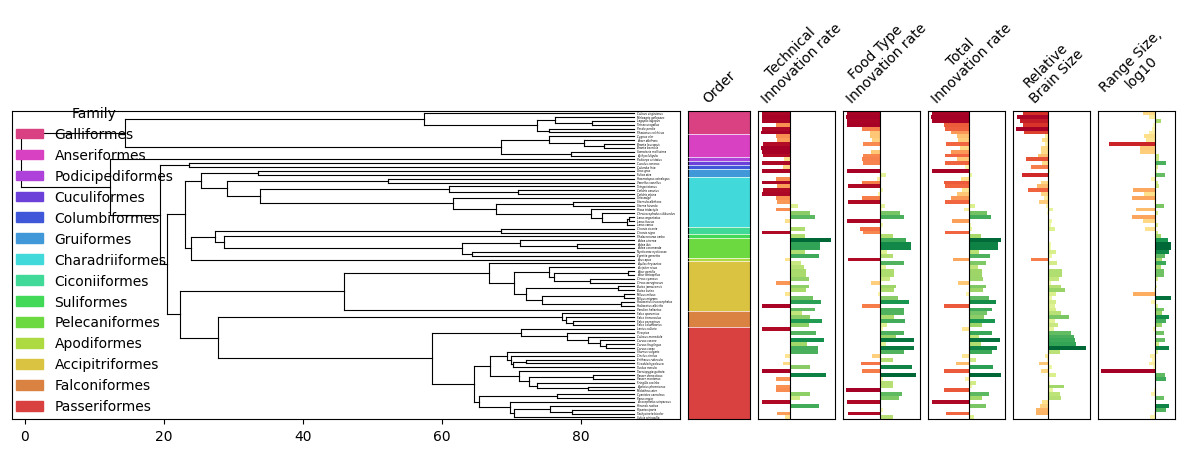

fig saved to tree_all_from_innobase_clootl_tree_new_pass_Order_common.pdf


In [19]:
tree_file = f"{PATH}/tree_clootl.newick"
tree = Tree(tree_file, format=1)

plot_tree_with_traits(
    df_with_2025_names_sample, 
    values_of_interest, 
    "common", 
    tree=tree,
    level="Order",
    row_size = 0.05
)

In [242]:
df_vgp = pd.read_csv(
    f"{PATH}/annotations.tsv", sep = "\t"
)
df_vgp_birds = df_vgp[df_vgp["Lineage"] == "Birds"]
df_vgp_birds["Species"] = df_vgp_birds["ScientificName"].str.replace(" ", "_")

df_vgp = df_with_2025_names_sample.merge(df_vgp_birds["Species"], on="Species", how="inner")
df_vgp

/var/folders/fc/n8rj9g1j6_x12_dl3p0fqv7c0000gn/T/ipykernel_46165/3801158042.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_vgp_birds["Species"] = df_vgp_birds["ScientificName"].str.replace(" ", "_")


,Species,FOODINNO2025_ResEff,TECHINNO2025_ResEff,TOTALINNOVATIONS2025_ResEff,Relative_brain_size,Order,Family
0,Agelaius_phoeniceus,1.823776,0.027581,1.251265,0.871304,Passeriformes,Icteridae (Troupials and Allies)
1,Ara_ararauna,1.445833,-0.730956,0.903842,2.555326,Psittaciformes,Psittacidae (New World and African Parrots)
2,Cinclus_cinclus,0.488804,0.676162,0.620814,-0.308838,Passeriformes,Cinclidae (Dippers)
3,Columba_livia,1.053208,0.532059,0.824551,-1.146871,Columbiformes,Columbidae (Pigeons and Doves)
4,Gallus_gallus,-0.289882,0.497506,0.104893,-2.260712,Galliformes,"Phasianidae (Pheasants, Grouse, and Allies)"
...,...,...,...,...,...,...,...
76,Chroicocephalus_ridibundus,2.315449,2.451633,2.218978,-0.139109,Charadriiformes,"Laridae (Gulls, Terns, and Skimmers)"
77,Netta_rufina,-0.905165,0.231915,-0.270242,-0.661554,Anseriformes,"Anatidae (Ducks, Geese, and Waterfowl)"
78,Platalea_leucorodia,0.000731,-0.855905,-0.369443,0.494720,Pelecaniformes,Threskiornithidae (Ibises and Spoonbills)
79,Sterna_hirundo,1.359476,1.589898,1.424611,-0.216017,Charadriiformes,"Laridae (Gulls, Terns, and Skimmers)"


In [303]:
vgp_tree_file = f"{PATH}/trees/roadies_v1.1.16b.nwk"
tree = Tree(vgp_tree_file, format=1)

for node in tree.traverse():
    if node.is_leaf():
        sp = df_vgp_birds[df_vgp_birds["# accession"] == node.name]["Species"].values

        if len(sp) > 0:
            node.name = sp[0]

In [ ]:
df_vgp_birds[df_vgp_birds["Species"] == node.name]

(73, 7)
73


/var/folders/fc/n8rj9g1j6_x12_dl3p0fqv7c0000gn/T/ipykernel_46165/3397511167.py:149: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap("RdYlGn")


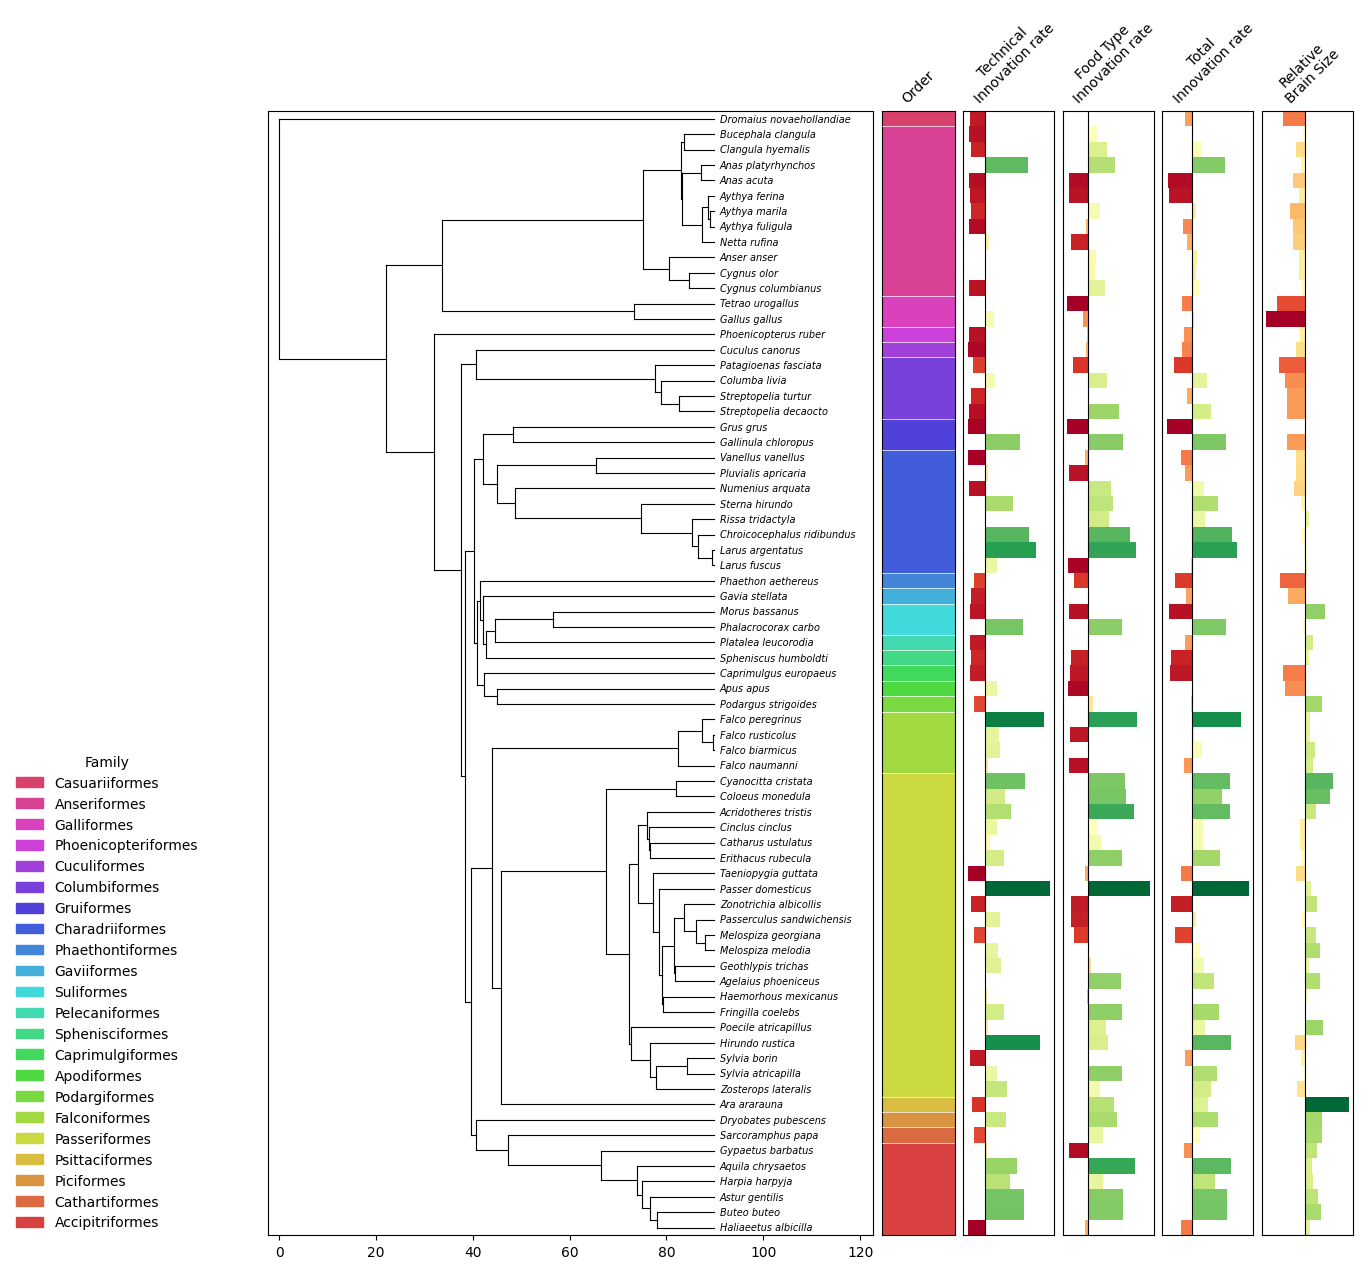

fig saved to tree_all_from_innobase_clootl_tree_new_pass_Order_common.pdf


In [321]:
plot_tree_with_traits(
    df_vgp, 
    values_of_interest, 
    name= "common", 
    level="Order",
    row_size = 0.2,
    tree = tree,
    fontsize = 7,
    figsize = 14,
    width_ratios_pan = 10,
    width_ratios_tree = 1.2,
    legend_loc = -12,
    narrow_tree_times = 1.3,
    sp_name_thr =1.1
)

In [118]:
fig.savefig(
    f"tree_all_from_innobase_clootl_tree_18.05.pdf", 
    format='pdf', 
    dpi=100,
    bbox_inches='tight'
)

In [127]:
# оставляем только нужные виды (как у тебя было)
from matplotlib import pyplot as plt

df = df_with_2025_names_sample[
    df_with_2025_names_sample["Species"].isin(overlaping_species)
].copy()

# группировка
grouped = df.copy().groupby("Order")
df.drop_duplicates(subset = "Order", inplace = True)

tree_order = Tree(f"{PATH}/tree_clootl.newick", format=1)
tree_order.prune(df["Species"].unique(), preserve_branch_length=True)
for l in tree_order.iter_leaves():
    sp = l.name
    order = df[df["Species"] == sp]["Order"].values[0]
    l.name = order

order_order = tree_order.get_leaf_names()

factor = 0.2  # уменьшаем до 30% от исходной длины
for leaf in tree_order.iter_leaves():
    leaf.dist = leaf.dist * factor

# species_order = tree.get_leaf_names()
# df = df.set_index("Species").loc[species_order].reset_index()


In [131]:
df_with_2025_names_sample[df_with_2025_names_sample["Species"].apply(lambda x: x.startswith("Corvus"))]


,Species,FOODINNO2025_ResEff,TECHINNO2025_ResEff,TOTALINNOVATIONS2025_ResEff,Relative_brain_size,Order,Family
194,Corvus_frugilegus,1.433962,2.250448,1.805722,1.616517,Passeriformes,"Corvidae (Crows, Jays, and Magpies)"
366,Corvus_brachyrhynchos,-0.738507,0.379595,-0.065164,1.767681,Passeriformes,"Corvidae (Crows, Jays, and Magpies)"
367,Corvus_brachyrhynchos,-0.738507,0.379595,-0.065164,1.767681,Passeriformes,"Corvidae (Crows, Jays, and Magpies)"
448,Corvus_brachyrhynchos,2.283132,3.291255,2.699024,1.460049,Passeriformes,"Corvidae (Crows, Jays, and Magpies)"
449,Corvus_brachyrhynchos,2.283132,3.291255,2.699024,1.460049,Passeriformes,"Corvidae (Crows, Jays, and Magpies)"
450,Corvus_corax,3.180981,3.062261,2.895060,2.237086,Passeriformes,"Corvidae (Crows, Jays, and Magpies)"
451,Corvus_corone,3.217497,3.502908,3.071782,1.560825,Passeriformes,"Corvidae (Crows, Jays, and Magpies)"
452,Corvus_ossifragus,0.841817,0.988976,1.055209,1.627125,Passeriformes,"Corvidae (Crows, Jays, and Magpies)"
578,Corvus_macrorhynchos,1.870691,2.270327,2.073163,2.133658,Passeriformes,"Corvidae (Crows, Jays, and Magpies)"
579,Corvus_splendens,2.476271,3.342199,2.815066,1.558173,Passeriformes,"Corvidae (Crows, Jays, and Magpies)"


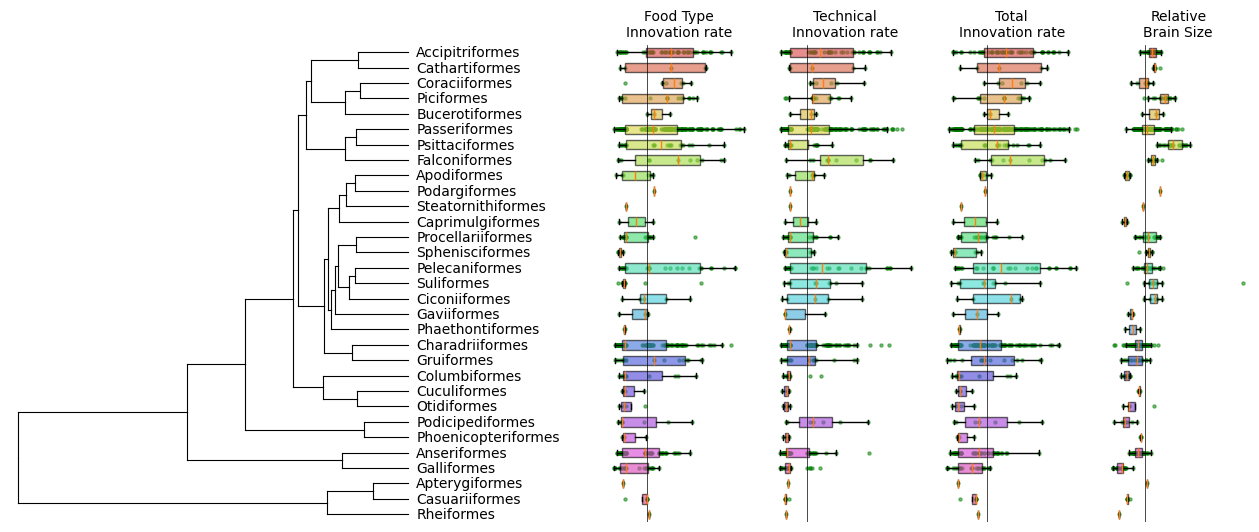

In [120]:
# orders = sorted(grouped.groups.keys())
orders = order_order  #df["Order"].drop_duplicates().tolist()

n_orders = len(orders)

y = np.arange(n_orders)

import matplotlib.colors as mcolors

colors = [
    mcolors.hsv_to_rgb((i/n_orders, 0.7, 0.85))
    for i in range(n_orders)
]

order_to_color = {
    order: colors[i]
    for i, order in enumerate(orders)
}

fig = plt.figure(figsize=(16, 0.2 * n_orders))

gs = fig.add_gridspec(
    1,
    len(values_of_interest) + 1,
    width_ratios=[4] + [1]*len(values_of_interest),
    wspace=0.1
)

ax_tree = fig.add_subplot(gs[0, 0])
ax_tree.axis('off')
for node in tree_order.traverse("postorder"):
    if node.is_leaf():
        node.y = order_order.index(node.name)
        node.x = 0
    else:
        node.y = np.mean([c.y for c in node.children])
        node.x = max(c.x + c.dist for c in node.children)

# mirror X
max_x = max(n.x for n in tree_order.traverse())
for node in tree_order.traverse():
    node.x = max_x - node.x

label_space = 0.45 * max_x
ax_tree.set_xlim(-0.02 * max_x, max_x + label_space)

for node in tree_order.traverse():
    if not node.is_root():
        ax_tree.plot([node.x, node.up.x], [node.y, node.y],
                     color="black", lw=0.8)
        ax_tree.plot([node.up.x, node.up.x], [node.y, node.up.y],
                     color="black", lw=0.8)


for sp, yy in zip(order_order, y):
    ax_tree.text(max_x + 0.02 * max_x, yy, sp,
                 va="center", fontsize=10)

ax_tree.set_ylim(-0.5, len(order_order) - 0.5)
ax_tree.invert_yaxis()
ax_tree.set_xticks([])
ax_tree.set_yticks([])

for i, val in enumerate(values_of_interest.keys()):
    ax = fig.add_subplot(gs[0, i+1], sharey=ax_tree)
    ax.axis('off')

    data = [
        grouped.get_group(order)[val].dropna()
        for order in orders
    ]

    bp = ax.boxplot(
        data,
        vert=False,
        positions=y,
        widths=0.6,
        patch_artist=True,
        showfliers=False
    )

    x_flat = []  # значения данных
    y_flat = []  # соответствующие позиции

    for i, (category_data, pos) in enumerate(zip(data, y)):
        x_flat.extend(category_data)
        y_flat.extend([pos] * len(category_data))

    # Теперь можно строить scatter
    sc = ax.scatter(x_flat, y_flat, color="green", alpha=0.5, s=5)

    # красим боксы в цвет Order
    for patch, order in zip(bp["boxes"], orders):
        patch.set_facecolor(order_to_color[order])
        patch.set_alpha(0.6)

    ax.set_title(values_of_interest[val], rotation=0, fontsize=10)
    ax.set_yticks([])
    ax.axvline(0, color="black", lw=0.5)

# axes = gs.subplots()
# for ax in axes.flat:
#     ax.axis('off')

fig.savefig(
    f"tree_orders_boxplots_with_points.pdf", 
    format='pdf', 
    dpi=100,
    bbox_inches='tight'
)

fig.savefig(
    f"tree_orders_boxplots_with_points.png", 
    format='png', 
    dpi=100,
    bbox_inches='tight'
)

In [124]:
df[df["Species"] == "Corvus_corax"]

,Species,FOODINNO2025_ResEff,TECHINNO2025_ResEff,TOTALINNOVATIONS2025_ResEff,Relative_brain_size,Order,Family


In [133]:
df_with_2025_names_sample.sort_values("TECHINNO2025_ResEff", ascending=False).head(20)

,Species,FOODINNO2025_ResEff,TECHINNO2025_ResEff,TOTALINNOVATIONS2025_ResEff,Relative_brain_size,Order,Family
773,Ardea_cinerea,2.673735,4.006954,3.127980,-0.086069,Pelecaniformes,"Ardeidae (Herons, Egrets, and Bitterns)"
71,Passer_domesticus,3.358285,3.661939,3.157251,0.367423,Passeriformes,Passeridae (Old World Sparrows)
451,Corvus_corone,3.217497,3.502908,3.071782,1.560825,Passeriformes,"Corvidae (Crows, Jays, and Magpies)"
579,Corvus_splendens,2.476271,3.342199,2.815066,1.558173,Passeriformes,"Corvidae (Crows, Jays, and Magpies)"
675,Falco_peregrinus,2.657775,3.340333,2.727485,0.298471,Falconiformes,Falconidae (Falcons and Caracaras)
449,Corvus_brachyrhynchos,2.283132,3.291255,2.699024,1.460049,Passeriformes,"Corvidae (Crows, Jays, and Magpies)"
448,Corvus_brachyrhynchos,2.283132,3.291255,2.699024,1.460049,Passeriformes,"Corvidae (Crows, Jays, and Magpies)"
477,Haliaeetus_leucocephalus,2.912749,3.270973,2.834962,0.409855,Accipitriformes,"Accipitridae (Hawks, Eagles, and Kites)"
425,Ardea_ibis,3.039193,3.219925,2.921952,0.086311,Pelecaniformes,"Ardeidae (Herons, Egrets, and Bitterns)"
426,Ardea_coromanda,3.039193,3.219925,2.921952,0.086311,Pelecaniformes,"Ardeidae (Herons, Egrets, and Bitterns)"
